# Import libs

In [8]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ensure project root (parent of 'src') is on sys.path when running from src/trees
cwd = Path.cwd()

while project_root.name != "src":
    project_root = project_root.parent
project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# verify import paths
print('CWD:', cwd)
print('Project root set to:', project_root)
print('sys.path ok? ', str(project_root) in sys.path)

from sklearn.metrics import mean_absolute_error
from src.trees.fastodt import FastODT
from src.trees.xfastodt import xFastODT

CWD: /home/wallace/Projects/DCL/Incremental-Learning-MycroftMinds/src/trees/tests
Project root set to: /home/wallace/Projects/DCL/Incremental-Learning-MycroftMinds
sys.path ok?  True


# Load Smoke Data

In [9]:
smoke_dir = project_root / 'smoke_data'
X_path = smoke_dir / 'X.npy'
y_path = smoke_dir / 'y.npy'
print('Smoke data dir:', smoke_dir)

X = np.load(X_path, allow_pickle=True)
Y = np.load(y_path, allow_pickle=True)
print('Raw shapes -> X:', X.shape, 'Y:', Y.shape)

# drop the first two columns
if X.ndim == 2 and X.shape[1] >= 3:
    X = X[:, 2:]
print('After slicing -> X:', X.shape)
print('Y stats -> min:', float(np.min(Y)), 'max:', float(np.max(Y)))

Smoke data dir: /home/wallace/Projects/DCL/Incremental-Learning-MycroftMinds/smoke_data
Raw shapes -> X: (19188, 41) Y: (19188,)
After slicing -> X: (19188, 39)
Y stats -> min: 72.91792481941697 max: 10742.596504799738


# Configure Shared Hyperparameters

In [10]:
depth = 15
grace_period = 10
split_confidence = 0.01
tie_threshold = 0.05
max_feature = 1.0
grace_period_depth = -1
bin_type = 'mean'
max_bins = 1
inherit_bins = False
split_criterion = 'vr_rel'
np.random.seed(42)
print('Config ->', {
    'depth': depth,
    'grace_period': grace_period,
    'split_confidence': split_confidence,
    'tie_threshold': tie_threshold,
    'max_feature': max_feature,
    'grace_period_depth': grace_period_depth,
    'bin_type': bin_type,
    'max_bins': max_bins,
    'inherit_bins': inherit_bins,
    'split_criterion': split_criterion,
})

Config -> {'depth': 15, 'grace_period': 10, 'split_confidence': 0.01, 'tie_threshold': 0.05, 'max_feature': 1.0, 'grace_period_depth': -1, 'bin_type': 'mean', 'max_bins': 1, 'inherit_bins': False, 'split_criterion': 'vr_rel'}


# Initialize Models (FastODT and xFastODT)

In [11]:
fast_model = FastODT(
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence,
    tie_threshold=tie_threshold,
    max_feature=max_feature,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    inherit_bins=inherit_bins,
    split_criterion=split_criterion,
 )

xfast_model = xFastODT(
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence,
    tie_threshold=tie_threshold,
    max_feature=max_feature,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    inherit_bins=inherit_bins,
    split_criterion=split_criterion,
 )
print('Models initialized.')

Models initialized.


# Train Models and Measure Time

## 1-by-1 training

In [12]:
iter = 0
for x,y in zip(X,Y):
    print(f'#{iter}. Fitting sample x:', x[:5], 'y:', y)
    fast_model.learn_one(x, y)
    xfast_model.learn_one(x, y)
    iter += 1

#0. Fitting sample x: [6 6 10 89.46114602819355 86.31904127975403] y: 89.90842761976454
#1. Fitting sample x: [6 6 10 89.46114602819355 88.86308997962887] y: 89.04829979208318
#2. Fitting sample x: [6 6 10 103.83530486478476 89.06215951774776] y: 89.8733630860795
#3. Fitting sample x: [6 6 10 89.04829979208318 88.43405935580044] y: 90.48586965873808
#4. Fitting sample x: [6 6 10 89.8733630860795 90.26419652398836] y: 89.65158004895483
#5. Fitting sample x: [7 6 10 90.48586965873808 112.32116764315576] y: 92.48828894685116
#6. Fitting sample x: [7 6 10 89.65158004895483 130.90856880174198] y: 90.43712915244184
#7. Fitting sample x: [7 6 10 92.48828894685116 91.57651631092465] y: 90.5899375563842
#8. Fitting sample x: [7 6 10 92.48828894685116 91.57651631092465] y: 91.41210689003016
#9. Fitting sample x: [7 6 10 90.5899375563842 122.58634100237995] y: 91.10997250614088
#10. Fitting sample x: [7 6 10 91.41210689003016 86.78823495541198] y: 87.41232462858311
#11. Fitting sample x: [7 6 10 

## Basic training (use basic or 1-by-1, not two!)

In [13]:
t0 = time.time()
fast_model.partial_fit(X, Y, verbose=False)
fast_train_time = time.time() - t0

t0 = time.time()
xfast_model.partial_fit(X, Y, verbose=False)
xfast_train_time = time.time() - t0

print(f"Training times -> FastODT: {fast_train_time:.3f}s | xFastODT: {xfast_train_time:.3f}s")

Training times -> FastODT: 0.145s | xFastODT: 0.151s


# Predict and Compute MAE

In [14]:
y_pred_fast = np.array([fast_model.predict(x) for x in X])
y_pred_xfast = np.array(xfast_model.predict(X))

mae_fast = mean_absolute_error(Y, y_pred_fast)
mae_xfast = mean_absolute_error(Y, y_pred_xfast)
print(f"MAE -> FastODT: {mae_fast:.4f} | xFastODT: {mae_xfast:.4f}")

MAE -> FastODT: 87.9758 | xFastODT: 102.4827


# Visualize a Slice of Predictions

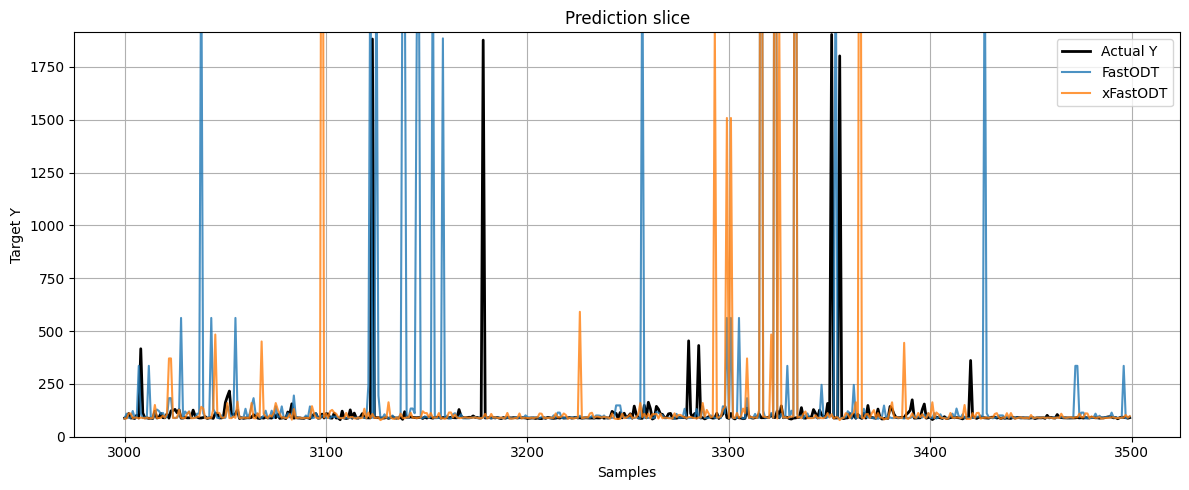

In [15]:
start = 3000
end = 3500
n = len(Y)
start = max(0, min(start, n-1))
end = max(start+1, min(end, n))

plt.figure(figsize=(12,5))
plt.plot(range(start, end), Y[start:end], label='Actual Y', color='black', linewidth=2)
plt.plot(range(start, end), y_pred_fast[start:end], label='FastODT', alpha=0.8)
plt.plot(range(start, end), y_pred_xfast[start:end], label='xFastODT', alpha=0.8)
plt.xlabel('Samples')
plt.ylabel('Target Y')
plt.title('Prediction slice')
plt.ylim(min(0, float(np.min(Y[start:end]))-5), float(np.max(Y[start:end]))+10)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Summarize Metrics

In [16]:
summary = pd.DataFrame([
    {
        'Model': 'FastODT',
        'Depth': depth,
        'Max Feature': max_feature,
        'Bin Type': bin_type,
        'Train Time (s)': round(fast_train_time, 4),
        'MAE': round(mae_fast, 4),
    },
    {
        'Model': 'xFastODT',
        'Depth': depth,
        'Max Feature': max_feature,
        'Bin Type': bin_type,
        'Train Time (s)': round(xfast_train_time, 4),
        'MAE': round(mae_xfast, 4),
    }
])
summary

,Model,Depth,Max Feature,Bin Type,Train Time (s),MAE
0,FastODT,15,1.0,mean,0.1453,87.9758
1,xFastODT,15,1.0,mean,0.1512,102.4827


In [10]:
fast_model.depth


4

In [27]:
fast_model.how_deep()

1

root

In [28]:
fast_model.root.show()
print("--------------------------------")
xfast_model.depths_containers[0][0].show()


feature: 19
threshold: 10.399999999999999
value: 237.44335758423105
--------------------------------
feature: 19
threshold: 10.399999999999999
value: 237.44335758423105


depth 1

In [29]:
fast_model.root.right.show()
print("--------------------------------")
xfast_model.depths_containers[1][1].show()

feature: 19
threshold: 10.39999999999982
value: 154.48632374589178
--------------------------------
feature: 19
threshold: 10.39999999999982
value: 154.48632374589178


depth 2

In [30]:
fast_model.root.right.right.show()
print("--------------------------------")
xfast_model.depths_containers[2][3].show()

feature: 6
threshold: 110.95061051875429
value: 116.95940679793658
--------------------------------
feature: 6
threshold: 110.95061051875429
value: 116.95940679793658


In [31]:
fast_model.root.right.left.show()
print("--------------------------------")
xfast_model.depths_containers[2][2].show()

feature: None
threshold: None
value: 154.48632374589178
--------------------------------
feature: None
threshold: None
value: 154.48632374589178


depth 3

In [32]:
fast_model.root.right.right.left.show()
print("--------------------------------")
xfast_model.depths_containers[3][6].show()

feature: 29
threshold: 8039.741273741786
value: 123.1020072534887
--------------------------------
feature: 29
threshold: 8039.741273741786
value: 123.1020072534887


In [17]:
fast_model.root.right.right.right.show()
print("--------------------------------")
xfast_model.depths_containers[3][7].show()

feature: 29
threshold: 8039.741273741786
value: 203.65549093345797
--------------------------------
feature: None
threshold: None
value: 204.44906726737224


In [18]:
xfast_model.depths_containers

[defaultdict(<function src.trees.xfastodt.xFastODT.__init__.<locals>.<lambda>()>,
             {0: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdcb5de450>}),
 defaultdict(<function src.trees.xfastodt.xFastODT.__init__.<locals>.<lambda>()>,
             {0: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdc7b31610>,
              1: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdc7b31750>}),
 defaultdict(<function src.trees.xfastodt.xFastODT.__init__.<locals>.<lambda>()>,
             {2: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdcb5e4d90>,
              3: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdcb701890>}),
 defaultdict(<function src.trees.xfastodt.xFastODT.__init__.<locals>.<lambda>()>,
             {6: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdcb7fe1d0>,
              7: <src.trees.xnode_hf.NodeHoeffdingBound at 0x1fdc763f9d0>})]